# TC5061: Baseline de Heart Disease (Cleveland)

**Autor:** Carlos Galvan  
**Curso:** TC5061  
**Dataset:** UCI Heart Disease, archivo `processed.cleveland.data` (303 filas)

En este notebook construyo un modelo baseline de regresión logística para detectar presencia de enfermedad cardiaca. Trabajo solo con el archivo procesado de Cleveland descargado del archivo oficial de UCI. Binarizo la variable `num` (0 = sin enfermedad, 1 a 4 = con enfermedad) porque esa es la decisión típica documentada en `heart-disease.names` para experimentos con este conjunto.


## 1. Carga y descripción del dataset

Descargué `processed.cleveland.data` y `heart-disease.names` desde archive.ics.uci.edu. El archivo de datos no trae encabezado; asigno los 14 nombres en el orden documentado. Los valores faltantes aparecen como `"?"`.


Ejecuto el notebook desde la carpeta del curso (`MLOps`). Ahi deben estar `data/processed.cleveland.data` y, al terminar, `mlflow_baseline.db`.


In [1]:
# Importaciones y rutas
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, f1_score, classification_report, confusion_matrix

import mlflow
import mlflow.sklearn

# Carpeta de trabajo: la misma donde esta este notebook (Documents/MNA/MLOps)
BASE = Path.cwd()
DATA = BASE / "data" / "processed.cleveland.data"
MLFLOW_DB = BASE / "mlflow_baseline.db"

COLUMNAS = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num",
]

df_raw = pd.read_csv(DATA, header=None, names=COLUMNAS, na_values="?")
print(f"Filas: {df_raw.shape[0]}")
print(f"Columnas: {df_raw.shape[1]}")
print("\nTipos de dato:")
print(df_raw.dtypes)
print("\nPrimeras filas:")
df_raw.head()


2026/10/04 00:44:56 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /workspace/.venv-tc5061/lib/python3.13/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


Filas: 303
Columnas: 14

Tipos de dato:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
num           int64
dtype: object

Primeras filas:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


### Significado de cada variable (segun heart-disease.names)

Tomo los significados del archivo oficial `heart-disease.names`, sin inventar definiciones:

| Variable | Significado |
|---|---|
| age | edad en años |
| sex | sexo (1 = male; 0 = female) |
| cp | tipo de dolor de pecho (1 typical angina, 2 atypical angina, 3 non-anginal pain, 4 asymptomatic) |
| trestbps | resting blood pressure en mm Hg al ingreso |
| chol | serum cholestoral en mg/dl |
| fbs | fasting blood sugar > 120 mg/dl (1 = true; 0 = false) |
| restecg | resting electrocardiographic results (0 normal, 1 ST-T abnormality, 2 left ventricular hypertrophy) |
| thalach | maximum heart rate achieved |
| exang | exercise induced angina (1 = yes; 0 = no) |
| oldpeak | ST depression induced by exercise relative to rest |
| slope | slope of the peak exercise ST segment (1 upsloping, 2 flat, 3 downsloping) |
| ca | number of major vessels (0-3) colored by flourosopy |
| thal | 3 = normal; 6 = fixed defect; 7 = reversable defect |
| num | diagnosis of heart disease (angiographic disease status): 0 = < 50% diameter narrowing; 1-4 = presencia de enfermedad |

La documentacion indica que los experimentos con Cleveland suelen distinguir presencia (valores 1, 2, 3, 4) de ausencia (valor 0). Por eso binarizo: `target = 0` si `num == 0`, y `target = 1` en otro caso.


In [2]:
# Binarizacion del objetivo documentada arriba
df = df_raw.copy()
df["target"] = (df["num"] != 0).astype(int)
print("Distribucion de num (original):")
print(df["num"].value_counts().sort_index())
print("\nDistribucion de target binario:")
print(df["target"].value_counts().sort_index())
print(f"\nProporcion enfermedad (target=1): {df['target'].mean():.3f}")


Distribucion de num (original):
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

Distribucion de target binario:
target
0    164
1    139
Name: count, dtype: int64

Proporcion enfermedad (target=1): 0.459


## 2. Análisis exploratorio (EDA)

Reviso estadisticos descriptivos y algunas gráficas que me ayudan a entender el balance del target, la edad y dos relaciones con el objetivo (`thalach` y `oldpeak`).


In [3]:
# Estadisticos descriptivos
df.describe(include="all")


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294,0.458746
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536,0.499120
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000,1.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000,1.000000


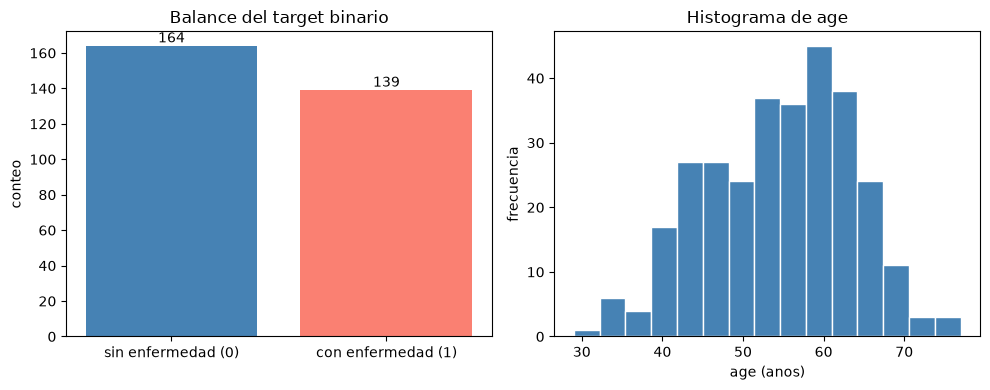

In [4]:
# Balance del target y histograma de edad
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

conteos = df["target"].value_counts().sort_index()
axes[0].bar(["sin enfermedad (0)", "con enfermedad (1)"], conteos.values, color=["steelblue", "salmon"])
axes[0].set_title("Balance del target binario")
axes[0].set_ylabel("conteo")
for i, v in enumerate(conteos.values):
    axes[0].text(i, v + 2, str(v), ha="center")

axes[1].hist(df["age"].dropna(), bins=15, color="steelblue", edgecolor="white")
axes[1].set_title("Histograma de age")
axes[1].set_xlabel("age (anos)")
axes[1].set_ylabel("frecuencia")

plt.tight_layout()
plt.show()


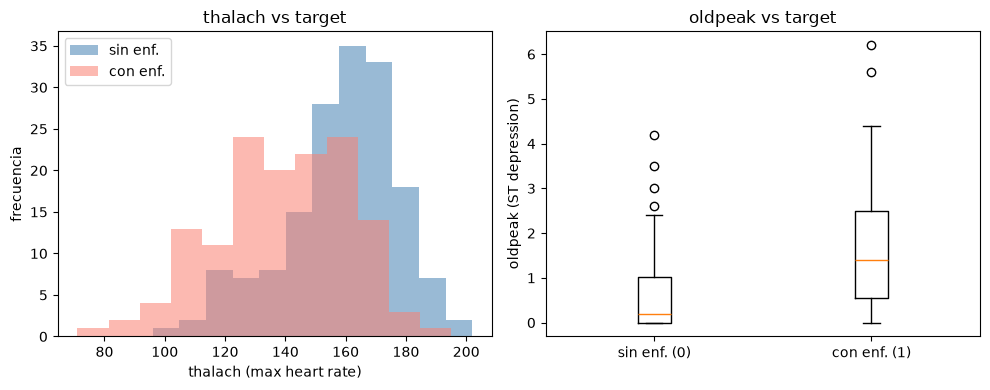

In [5]:
# Relacion thalach y oldpeak vs target
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for t, label, color in [(0, "sin enf.", "steelblue"), (1, "con enf.", "salmon")]:
    subset = df.loc[df["target"] == t, "thalach"].dropna()
    axes[0].hist(subset, bins=12, alpha=0.55, label=label, color=color)
axes[0].set_title("thalach vs target")
axes[0].set_xlabel("thalach (max heart rate)")
axes[0].set_ylabel("frecuencia")
axes[0].legend()

data_box = [df.loc[df["target"] == 0, "oldpeak"].dropna(),
            df.loc[df["target"] == 1, "oldpeak"].dropna()]
axes[1].boxplot(data_box, tick_labels=["sin enf. (0)", "con enf. (1)"])
axes[1].set_title("oldpeak vs target")
axes[1].set_ylabel("oldpeak (ST depression)")

plt.tight_layout()
plt.show()


Observo que el target está relativamente equilibrado (164 sin enfermedad y 139 con enfermedad en el archivo crudo). La edad se concentra alrededor de los 50-60 años. En `thalach`, los casos con enfermedad tienden a valores algo más bajos; en `oldpeak`, la mediana sube cuando hay enfermedad. Esas dos señales son útiles para un baseline lineal.


## 3. Limpieza

Decisiones que tomo aqui, en primera persona:

1. **Valores `"?"`:** aparecen en `ca` y `thal`. Los lei como NaN al cargar. Como son pocas filas incompletas y esas variables son predictoras importantes según la literatura del dataset, **elimino las filas con NaN** en lugar de imputar (no quiero inventar valores clinicos en un baseline).
2. **Duplicados:** reviso y, si existen, los elimino.
3. **Tipos:** despues de quitar `"?"`, convierto `ca` y `thal` a numerico.
4. **Outliers (IQR) en columnas continuas** (`age`, `trestbps`, `chol`, `thalach`, `oldpeak`): calculo el rango intercuartil. **Decido conservar las filas** (no las elimino ni las suelo) porque en un contexto clinico valores extremos de colesterol o presion pueden ser reales y utiles para el modelo; documentar el conteo me basta para el baseline.


In [6]:
# Conteo de faltantes y duplicados antes de limpiar
print("Filas antes de limpieza:", len(df))
print("NaN por columna:")
print(df.isna().sum())
print("Duplicados exactos:", df.duplicated().sum())

n_antes = len(df)
df_clean = df.dropna().copy()
n_despues_na = len(df_clean)
print(f"\nFilas eliminadas por NaN: {n_antes - n_despues_na}")
print(f"Filas tras dropna: {n_despues_na}")

# Asegurar dtypes numericos en ca y thal
df_clean["ca"] = pd.to_numeric(df_clean["ca"])
df_clean["thal"] = pd.to_numeric(df_clean["thal"])

# Deteccion de outliers IQR (solo reporte; los conservo)
continuas = ["age", "trestbps", "chol", "thalach", "oldpeak"]
outlier_mask = pd.Series(False, index=df_clean.index)
print("\nOutliers por IQR (1.5 * IQR):")
for col in continuas:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (df_clean[col] < low) | (df_clean[col] > high)
    outlier_mask = outlier_mask | mask
    print(f"  {col}: {mask.sum()} fuera de [{low:.1f}, {high:.1f}]")

print(f"Filas con al menos un outlier continuo: {outlier_mask.sum()}")
print("Decision: CONSERVO todas esas filas (no capping, no drop).")

# Quitar num original; el modelo usa target
features = [c for c in COLUMNAS if c != "num"]
X = df_clean[features]
y = df_clean["target"]

print(f"\nFilas finales para modelado: {len(df_clean)}")
print(f"Balance target limpio:\n{y.value_counts().sort_index()}")
print("dtypes finales:")
print(df_clean[features + ["target"]].dtypes)


Filas antes de limpieza: 303
NaN por columna:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
target      0
dtype: int64
Duplicados exactos: 0

Filas eliminadas por NaN: 6
Filas tras dropna: 297

Outliers por IQR (1.5 * IQR):
  age: 0 fuera de [28.5, 80.5]
  trestbps: 9 fuera de [90.0, 170.0]
  chol: 5 fuera de [113.5, 373.5]
  thalach: 1 fuera de [83.5, 215.5]
  oldpeak: 5 fuera de [-2.4, 4.0]
Filas con al menos un outlier continuo: 19
Decision: CONSERVO todas esas filas (no capping, no drop).

Filas finales para modelado: 297
Balance target limpio:
target
0    160
1    137
Name: count, dtype: int64
dtypes finales:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca      

## 4. División train/test y modelo baseline

Uso `train_test_split` con `test_size=0.2`, `random_state=42` y `stratify=y`. El modelo es `LogisticRegression(max_iter=1000)` con `C=1.0` (default).


In [7]:
# Split estratificado y entrenamiento
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train: {X_train.shape[0]} filas | Test: {X_test.shape[0]} filas")
print(f"Proporcion target train: {y_train.mean():.3f} | test: {y_test.mean():.3f}")

modelo = LogisticRegression(max_iter=1000, C=1.0, random_state=42)
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)


Train: 237 filas | Test: 60 filas
Proporcion target train: 0.460 | test: 0.467


## 5. Métricas

Reporto accuracy, recall (clase positiva = enfermedad) y F1. En un problema de cribado medico me importa más el **recall** de la clase con enfermedad: quiero minimizar falsos negativos (personas enfermas clasificadas como sanas). Accuracy da una vista general, pero no basta sola si el costo de errar hacia "sano" es alto.


In [8]:
# Metricas reales del run
acc = accuracy_score(y_test, y_pred)
rec = recall_score(y_test, y_pred, pos_label=1)
f1 = f1_score(y_test, y_pred, pos_label=1)
cm = confusion_matrix(y_test, y_pred)

print(f"Accuracy: {acc:.4f}")
print(f"Recall (enfermedad=1): {rec:.4f}")
print(f"F1 (enfermedad=1): {f1:.4f}")
print("\nMatriz de confusion [[TN FP],[FN TP]]:")
print(cm)
print("\nReporte de clasificacion:")
print(classification_report(y_test, y_pred, target_names=["sin enf. (0)", "con enf. (1)"]))


Accuracy: 0.8333
Recall (enfermedad=1): 0.7857
F1 (enfermedad=1): 0.8148

Matriz de confusion [[TN FP],[FN TP]]:
[[28  4]
 [ 6 22]]

Reporte de clasificacion:
              precision    recall  f1-score   support

sin enf. (0)       0.82      0.88      0.85        32
con enf. (1)       0.85      0.79      0.81        28

    accuracy                           0.83        60
   macro avg       0.83      0.83      0.83        60
weighted avg       0.83      0.83      0.83        60



Con los numeros reales de este run sobre el test (60 filas: 32 sin enfermedad, 28 con enfermedad):

- **Accuracy = 0.8333** (50 de 60 bien clasificados).
- **Recall (clase 1) = 0.7857**: de 28 pacientes con enfermedad, el modelo recupero 22 y dejo pasar 6 (falsos negativos).
- **F1 (clase 1) = 0.8148**.
- Matriz de confusion: TN=28, FP=4, FN=6, TP=22.

Para cribado medico priorizo el recall. Un recall de 0.7857 indica que cerca de 1 de cada 5 personas con enfermedad en el test no seria detectada. Aunque el accuracy (0.8333) se ve aceptable para un baseline lineal, esos 6 falsos negativos son el costo clinico que mas me preocupa. El F1 de 0.8148 resume precision (0.85 en la clase 1) y recall; esta equilibrado, pero no sustituye mirar el recall solo cuando el objetivo es no dejar pasar casos positivos.


## 6. MLflow Tracking

Registro el experimento `TC5061_baseline_heart` en una base SQLite local (`mlflow_baseline.db`). Guardo parametros, metricas y el modelo sklearn.


In [9]:
# Tracking MLflow local (sqlite)
mlflow.set_tracking_uri(f"sqlite:///{MLFLOW_DB}")
mlflow.set_experiment("TC5061_baseline_heart")

with mlflow.start_run(run_name="logreg_baseline") as run:
    mlflow.log_param("model", "LogisticRegression")
    mlflow.log_param("test_size", 0.2)
    mlflow.log_param("random_state", 42)
    mlflow.log_param("C", 1.0)
    mlflow.log_param("max_iter", 1000)
    mlflow.log_param("n_rows_raw", int(n_antes))
    mlflow.log_param("n_rows_clean", int(len(df_clean)))

    mlflow.log_metric("accuracy", float(acc))
    mlflow.log_metric("recall", float(rec))
    mlflow.log_metric("f1", float(f1))

    try:
        mlflow.sklearn.log_model(modelo, artifact_path="model")
        print("Modelo registrado con mlflow.sklearn.log_model")
    except Exception as e:
        print(f"No pude loguear el modelo con log_model: {e}")

    run_id = run.info.run_id
    print(f"MLflow run_id: {run_id}")
    print(f"Tracking URI: sqlite:///{MLFLOW_DB}")
    print(f"Experiment: TC5061_baseline_heart")
    print(f"Metrics -> accuracy={acc:.4f}, recall={rec:.4f}, f1={f1:.4f}")


2026/10/04 00:44:58 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Modelo registrado con mlflow.sklearn.log_model
MLflow run_id: 72a9a072ca234c519c341d5e4eb8088a
Tracking URI: sqlite:////workspace/entregas/mna/tc5061/mlflow_baseline.db
Experiment: TC5061_baseline_heart
Metrics -> accuracy=0.8333, recall=0.7857, f1=0.8148


La captura siguiente es la interfaz de MLflow del run `logreg_baseline`. Ahí se ven los parámetros y las métricas accuracy, recall y f1.


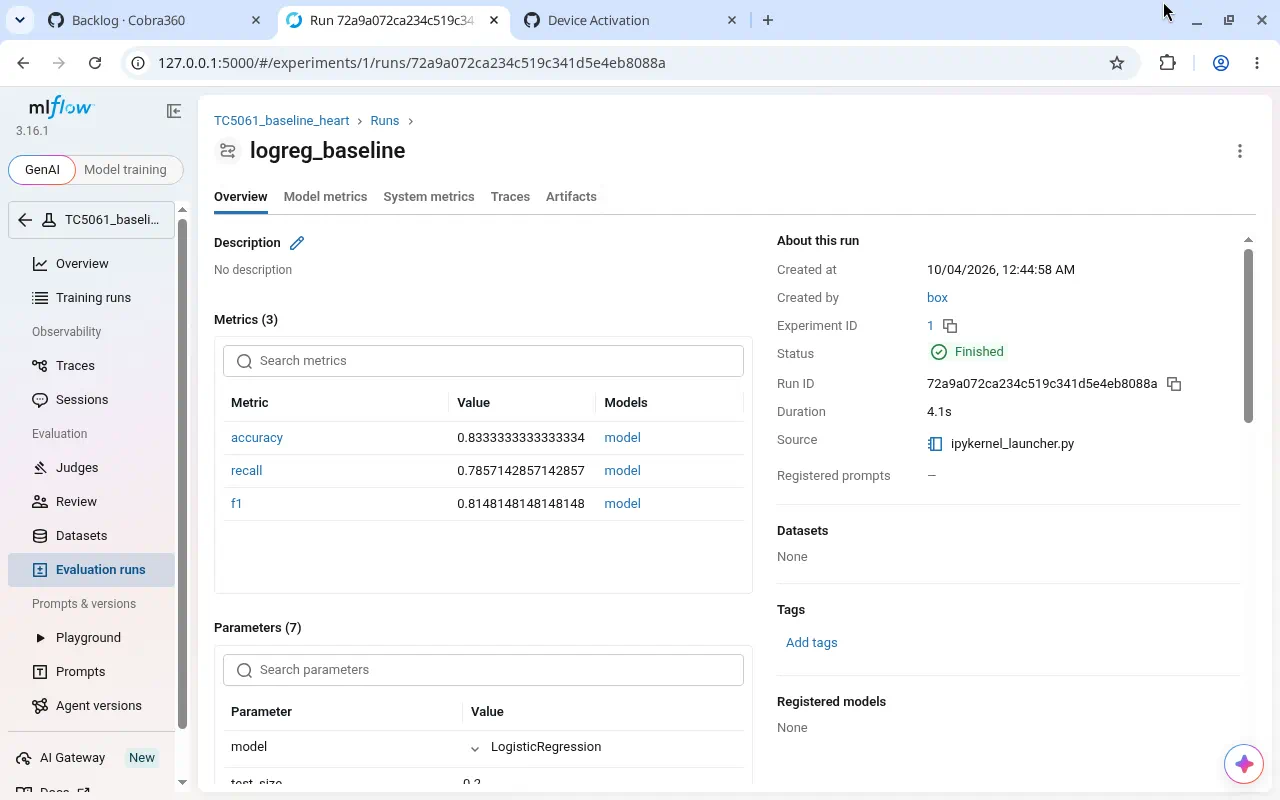

In [1]:
# Captura de la interfaz de MLflow (experimento TC5061_baseline_heart)
from IPython.display import Image, display
display(Image(filename=str(BASE / "mlflow_ui_baseline.png")))


## 7. Reflexión

Trabajé este notebook como un baseline corto, pero al cerrarlo pienso en lo que me costaría reproducirlo dentro de unos meses. Hoy el dataset vive en una carpeta local con el archivo de Cleveland que bajé de UCI; si alguien cambia ese CSV o lo reemplaza por otra versión, mis métricas dejan de ser comparables. Por eso, en un flujo MLOps real yo versionaría el dataset (hash del archivo, fecha de descarga y URL oficial) y guardaría esa referencia junto al run de MLflow. También fijaría el split: ya use `random_state=42` y `stratify`, pero conviene persistir los indices de train y test o un seed documentado en el mismo experimento, para no reentrenar "parecido" y creer que mejore cuando solo movi la partición. El tracking con SQLite me dejó el run al lado de accuracy, recall y F1; esa cercania entre codigo, parametros y metricas es lo que después me permite auditar por qué un modelo salio distinto. Como data scientist, cuando me pidan reproducir un modelo clinico no basta con recordar "use regresión logística": necesito el mismo archivo, el mismo criterio de limpieza (aquí eliminé filas con `?` en `ca`/`thal` y conserve outliers), el mismo binarizado de `num`, y el mismo run_id. Sin eso, cualquier mejora posterior se vuelve anécdota. Este ejercicio me deja una plantilla mínima: datos fijos, split fijo, métricas reales registradas, y una nota clara de cada decision de limpieza para poder repetir el trabajo sin adivinar.
